# Regime-Aware News Trading — données
WTI quotidien, 2010 → avril 2024 (fin des futures M1/M2 publiés par l'EIA).

In [1]:
# !pip install yfinance xlrd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

START, END = "2010-01-01", "2024-04-05"
UA = {"User-Agent": "Mozilla/5.0"}

def eia(code):   # séries historiques EIA (xls public, sans clé)
    url = f"https://www.eia.gov/dnav/pet/hist_xls/{code}.xls"
    return pd.read_excel(url, sheet_name="Data 1", skiprows=2, index_col=0, storage_options=UA).squeeze("columns")

import urllib.request

def fred(code):  # sans faux User-Agent, et coupe au bout de 30 s au lieu de bloquer
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={code}"
    with urllib.request.urlopen(url, timeout=30) as f:
        return pd.read_csv(f, index_col=0, parse_dates=True, na_values=".").squeeze("columns")

In [2]:
# 1. Marché : prix + volume (Yahoo), contrats NYMEX M1 et M2 (EIA)
raw = yf.download(["CL=F", "BZ=F"], start=START, end=END, progress=False)
mkt = pd.DataFrame({
    "wti": raw["Close"]["CL=F"],
    "brent": raw["Close"]["BZ=F"],
    "volume": raw["Volume"]["CL=F"],
    "m1": eia("RCLC1d"),
    "m2": eia("RCLC2d"),
}).loc[START:END]

In [3]:
# 2. Macro pour les régimes (FRED) : taux 10 ans, inflation anticipée, spread crédit Baa, dollar
macro = pd.concat({c: fred(c) for c in ["DGS10", "T10YIE", "BAA10Y", "DTWEXBGS"]}, axis=1)

In [4]:
# 3. Événements : rapport hebdo EIA sur les stocks de brut US hors SPR
stocks = eia("WCESTUS1w") / 1e3                     # millions de barils, semaine finissant le vendredi
d = stocks.diff()
seas = d.groupby(d.index.isocalendar().week).transform(lambda s: s.shift(1).rolling(5).mean())
ev = (d - seas).rename("surprise")                  # variation - moyenne des 5 années précédentes, même semaine
ev.index = ev.index + pd.Timedelta(days=5)          # publié le mercredi suivant, 10h30 ET (décalages fériés ignorés)

In [5]:
# 4. Table quotidienne, alignée sur les jours de cotation du WTI
df = mkt.dropna(subset=["wti"])
df = df.join(macro.ffill().reindex(df.index, method="ffill"))
df["r"] = np.log(df["wti"].where(df["wti"] > 0)).diff()       # log-rendement (prix < 0 du 20/04/2020 exclu)
df["vol21"] = df["r"].rolling(21).std() * np.sqrt(252)          # vol réalisée annualisée
df["slope"] = np.log(df["m1"].where(df["m1"] > 0) / df["m2"])   # > 0 backwardation, < 0 contango
df["surprise"] = ev.reindex(df.index)                           # NaN hors jours de publication
df.tail()

,wti,brent,volume,m1,m2,DGS10,T10YIE,BAA10Y,DTWEXBGS,r,vol21,slope,surprise
Date,,,,,,,,,,,,,
2024-03-28,83.169998,87.480003,293774.0,83.17,82.42,4.20,2.32,1.50,121.0635,0.022126,0.221963,0.009059,NaN
2024-04-01,83.709999,87.419998,321059.0,83.71,82.82,4.33,2.35,1.49,121.5151,0.006472,0.221097,0.010689,NaN
2024-04-02,85.150002,88.919998,344040.0,85.15,84.22,4.36,2.36,1.51,121.3035,0.017056,0.216837,0.010982,NaN
2024-04-03,85.430000,89.349998,322549.0,85.43,84.61,4.36,2.36,1.49,121.0198,0.003283,0.206156,0.009645,-0.0362
2024-04-04,86.589996,90.650002,359534.0,86.59,85.81,4.31,2.34,1.51,120.7613,0.013487,0.204350,0.009049,NaN


In [6]:
# Sauvegarde locale : sources brutes + table finale dans data/
import os
os.makedirs("data", exist_ok=True)
mkt.to_csv("data/market.csv")
macro.to_csv("data/macro.csv")
stocks.to_csv("data/eia_stocks.csv")
df.to_csv("data/dataset.csv")

In [7]:
# 5. Analyse rapide
print(df.isna().sum())
df.describe().T.round(3)

wti            0
brent         32
volume         0
m1            12
m2            10
DGS10          0
T10YIE         0
BAA10Y         0
DTWEXBGS       0
r              3
vol21         43
slope         13
surprise    2849
dtype: int64


,count,mean,std,min,25%,50%,75%,max
wti,3585.0,71.832,21.858,-37.630,52.740,72.760,90.800,123.700
brent,3553.0,78.050,24.661,19.330,57.880,76.320,102.640,127.980
volume,3585.0,406656.732,205767.340,0.000,266915.000,352887.000,523793.000,2288230.000
m1,3573.0,71.871,21.855,-37.630,52.750,72.840,90.820,123.700
m2,3575.0,72.060,21.414,11.570,53.235,72.770,90.785,119.780
DGS10,3585.0,2.410,0.865,0.520,1.800,2.330,2.920,4.980
T10YIE,3585.0,2.043,0.353,0.500,1.790,2.110,2.300,3.020
BAA10Y,3585.0,2.453,0.494,1.490,2.070,2.370,2.820,4.310
DTWEXBGS,3585.0,107.071,11.595,85.469,93.751,111.563,116.022,128.454
r,3582.0,0.000,0.026,-0.282,-0.012,0.001,0.012,0.320


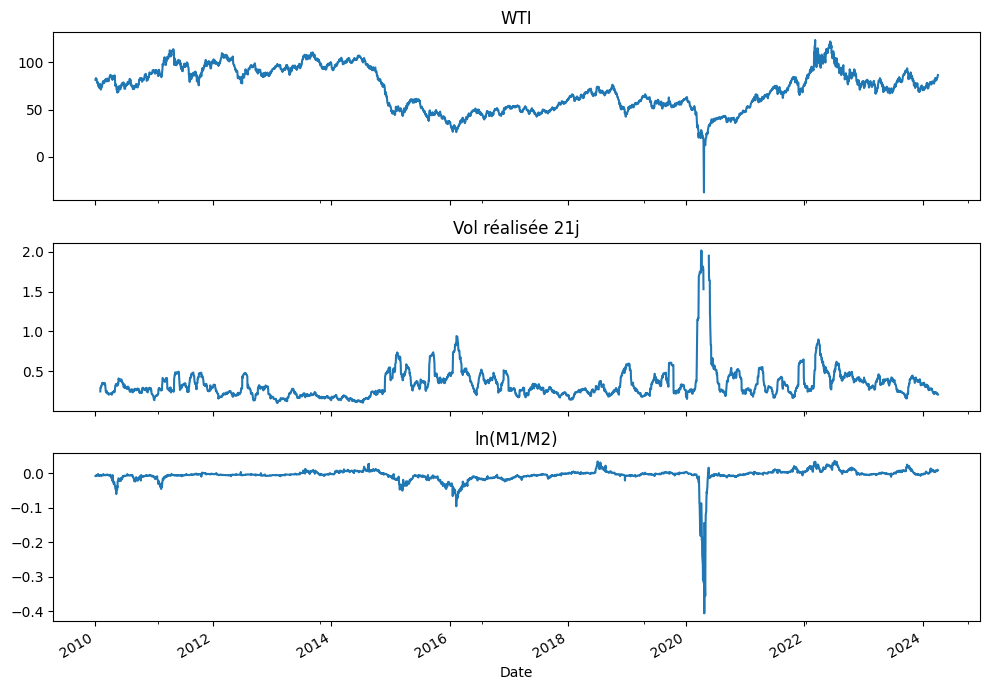

In [8]:
fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
df["wti"].plot(ax=ax[0], title="WTI")
df["vol21"].plot(ax=ax[1], title="Vol réalisée 21j")
df["slope"].plot(ax=ax[2], title="ln(M1/M2)")
plt.tight_layout()

In [9]:
# Le rapport EIA fait-il bouger le prix ? (close-to-close du jour de publication)
jour_eia = df["surprise"].notna()
print(df.groupby(jour_eia)["r"].std().rename({False: "autres jours", True: "jours EIA"}).round(4))
print("corr(surprise stocks, r) =", round(df["surprise"].corr(df["r"]), 3))

surprise
autres jours    0.0252
jours EIA       0.0294
Name: r, dtype: float64
corr(surprise stocks, r) = -0.09


In [10]:
import statsmodels.formula.api as smf

lvl = stocks.shift(1).set_axis(stocks.index + pd.Timedelta(days=5))  # stock de la semaine d'avant, daté au jour de publication
e = pd.DataFrame({
    "r": 100 * df["r"],                                  # rendement du jour de publication, en %
    "S": 100 * df["surprise"] / lvl.reindex(df.index),   # surprise en % du stock -> coef = élasticité
    "B": (df["slope"].shift(1) > 0).astype(int),         # 1 si backwardation la veille (connu avant 10h30)
}).dropna()

m = smf.ols("r ~ S * B", data=e).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print(m.summary().tables[1])
print(m.t_test("S + S:B = 0"))     # effet total en backwardation
print(e["B"].value_counts())

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1735      0.151      1.146      0.252      -0.123       0.470
S             -0.2860      0.176     -1.624      0.104      -0.631       0.059
B             -0.2462      0.200     -1.229      0.219      -0.639       0.147
S:B            0.1136      0.223      0.510      0.610      -0.323       0.550
                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.1724      0.134     -1.287      0.198      -0.435       0.090
B
0    500
1    236
Name: count, dtype: int64


In [11]:
train, test = e[:"2017"], e["2018":]
for f in ["r ~ S", "r ~ S * B"]:
    pred = smf.ols(f, data=train).fit().predict(test)
    r2 = 1 - ((test["r"] - pred) ** 2).sum() / ((test["r"] - train["r"].mean()) ** 2).sum()
    print(f"{f:10s} R2 hors échantillon = {r2:.4f}")

r ~ S      R2 hors échantillon = -0.0239
r ~ S * B  R2 hors échantillon = -0.0201


In [12]:
print(smf.ols("np.abs(r) ~ np.abs(S)", data=e).fit(cov_type="HAC", cov_kwds={"maxlags": 4}).summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.6683      0.135     12.326      0.000       1.403       1.934
np.abs(S)      0.2581      0.154      1.681      0.093      -0.043       0.559


In [ ]:
#!pip install dukascopy-python
import os, dukascopy_python as dk
from dukascopy_python.instruments import INSTRUMENT_CMD_ENERGY_E_LIGHT as WTI_CFD
from pandas.tseries.holiday import USFederalHolidayCalendar

H = [5, 15, 30, 60]                                   # horizons en minutes après 10h30
fer = USFederalHolidayCalendar().holidays("2012-12-01", END)
pub = [d for d in ev.loc["2013":END].dropna().index   # mercredis de publication depuis 2013
       if not ((fer >= d - pd.Timedelta(days=2)) & (fer <= d)).any()]   # semaines avec férié exclues (rapport décalé)

def window(d):  # prix 1 min de 10h25 à 11h35 heure de New York
    t0 = pd.Timestamp(f"{d:%Y-%m-%d} 10:25", tz="America/New_York")
    b = dk.fetch(WTI_CFD, dk.INTERVAL_MIN_1, dk.OFFER_SIDE_BID, t0, t0 + pd.Timedelta(minutes=70), limit=100)
    return b["close"].tz_convert("America/New_York").tz_localize(None).asfreq("1min").ffill()

if os.path.exists("data/eia_intraday.csv"):           # cache
    intra = pd.read_csv("data/eia_intraday.csv", index_col=0, parse_dates=True)
else:
    rows = {}
    for d in pub:
        p, t = window(d), d + pd.Timedelta("10:29:00")   # close de la barre 10h29 = dernier prix avant publication
        if t in p.index and t + pd.Timedelta(minutes=60) in p.index:
            rows[d] = {f"r{h}": 100 * np.log(p[t + pd.Timedelta(minutes=h)] / p[t]) for h in H}
    intra = pd.DataFrame.from_dict(rows, orient="index")
    intra.to_csv("data/eia_intraday.csv")
intra.describe().round(3)


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


,r5,r15,r30,r60
count,492.000,492.000,492.000,492.000
mean,-0.031,-0.002,0.019,-0.029
std,0.686,0.907,1.071,1.130
min,-3.557,-3.377,-3.052,-4.425
25%,-0.383,-0.476,-0.515,-0.602
50%,-0.025,-0.008,-0.012,-0.003
75%,0.328,0.473,0.552,0.641
max,2.612,8.283,10.202,3.936


In [14]:
e2 = e.join(intra, how="inner")
print(e2[["r", "r30"]].std().round(2), "\n")         # bruit : journalier vs 30 min

res = {h: smf.ols(f"r{h} ~ S * B", data=e2).fit(cov_type="HAC", cov_kwds={"maxlags": 4}) for h in H}
pd.DataFrame({f"{h} min": pd.concat([m.params, m.pvalues], keys=["coef", "p"]) for h, m in res.items()}).round(3)

r      3.27
r30    1.07
dtype: float64 



5 min  15 min  30 min  60 min
coef Intercept -0.031  -0.010   0.004  -0.038
     S         -0.223  -0.140  -0.134  -0.163
     B         -0.003   0.015   0.031   0.025
     S:B        0.122   0.068   0.082   0.102
p    Intercept  0.415   0.860   0.954   0.557
     S          0.000   0.055   0.101   0.009
     B          0.960   0.832   0.715   0.771
     S:B        0.008   0.405   0.378   0.186

In [15]:
e2["V"] = 100 * df["vol21"].shift(1).reindex(e2.index)          # vol réalisée de la veille, en %
specs = {"base": ("r5 ~ S * B", e2),
         "sans 2020": ("r5 ~ S * B", e2.drop(e2.loc["2020"].index)),
         "contrôle vol": ("r5 ~ S * B + S:V + V", e2)}
out = {}
for k, (f, d) in specs.items():
    m = smf.ols(f, data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    out[k] = pd.concat([m.params, m.pvalues], keys=["coef", "p"])
pd.DataFrame(out).round(3)

base  sans 2020  contrôle vol
coef B         -0.003      0.015         0.018
     Intercept -0.031     -0.043        -0.069
     S         -0.223     -0.248        -0.230
     S:B        0.122      0.144         0.131
     S:V          NaN        NaN        -0.000
     V            NaN        NaN         0.001
p    B          0.960      0.776         0.707
     Intercept  0.415      0.292         0.268
     S          0.000      0.000         0.000
     S:B        0.008      0.007         0.008
     S:V          NaN        NaN         0.854
     V            NaN        NaN         0.701